# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
SURNAME_NAME = 'Олійник Божена'
GROUP        = 'ШІ-33'
NUMBER       = 7

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Олійник Божена | ШІ-33 | номер 7


In [2]:
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 7   ·   Олійник Божена   ·   ШІ-33

   Ринок:  Kirovohrad
   Товар:  яйця   (у наборі даних: Eggs - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | 30.10.2026 |
| **Підпис** | О.Б.О |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

mpl.rcParams.update({'font.family': 'DejaVu Sans', 'figure.figsize': (11, 3.8),
                     'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False,
                     'axes.spines.right': False})
N_FOLDS, H = 7, 3 
ORDER = (1, 1, 1)

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))
GRID = pd.date_range('2014-03-01', '2017-12-01', freq='MS')

raw = (prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
       .sort_values('date').set_index('date')['ціна'])
print(MARKET, '|', GOOD, '| одиниця:', prices.loc[(prices['ринок']==MARKET)&(prices['товар']==GOOD),'одиниця'].iloc[0], '| валюта: UAH')

s = raw.reindex(GRID)                     # повна місячна сітка
print('Місяців у сітці:', len(GRID), '| з виміром:', s.notna().sum(), '| без виміру:', s.isna().sum())
print('Пропущені місяці у ряді:', [d.strftime('%m.%Y') for d in s.index[s.isna()]])

per_month = prices.groupby('date').size().reindex(GRID, fill_value=0)
print('\nКількість рядків набору у серпні 2017:', per_month['2017-08-01'], '(у липні 2017:', per_month['2017-07-01'], ', у вересні 2017:', per_month['2017-09-01'], ')')
print('Місяців, у яких набір не має жодного виміру:', [d.strftime('%m.%Y') for d in per_month.index[per_month == 0]])
print('\nМісяці поруч із пропуском:'); print(s['2017-06-01':'2017-10-01'].round(3))

Kirovohrad | Eggs - Retail | одиниця: 10 pcs | валюта: UAH
Місяців у сітці: 46 | з виміром: 45 | без виміру: 1
Пропущені місяці у ряді: ['08.2017']

Кількість рядків набору у серпні 2017: 0 (у липні 2017: 650 , у вересні 2017: 650 )
Місяців, у яких набір не має жодного виміру: ['08.2017']

Місяці поруч із пропуском:
2017-06-01    13.030
2017-07-01    10.253
2017-08-01       NaN
2017-09-01    18.927
2017-10-01    21.483
Freq: MS, Name: ціна, dtype: float64


**Висновок до завдання 1:**

Повна місячна сітка 03.2014 – 12.2017 містить **46 місяців**, із них **45 мають вимір**; **один пропуск — серпень 2017**.
Причина — не у Кіровоградському ринку: у всьому наборі за серпень 2017 немає **жодного** рядка (у липні та вересні 2017 — по 650 рядків), тобто в джерелі просто відсутня серпнева хвиля збору цін. Тому пропуск є в усіх рядах без винятку, а в моєму він **єдиний** (сітку побудовано правильно: пропусків усередині ряду більше немає). Якби я працював без реіндексації на повну сітку, ряд мав би 45 точок і «пропуску» не було б видно взагалі — саме так помиляється звіт колеги в завданні 9.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

Значення за серпень 2017, грн за 10 шт:
перенесення останнього (ffill)    10.253
лінійна інтерполяція              14.590
середнє по всьому ряду            14.881
Name: 2017-08-01 00:00:00, dtype: float64


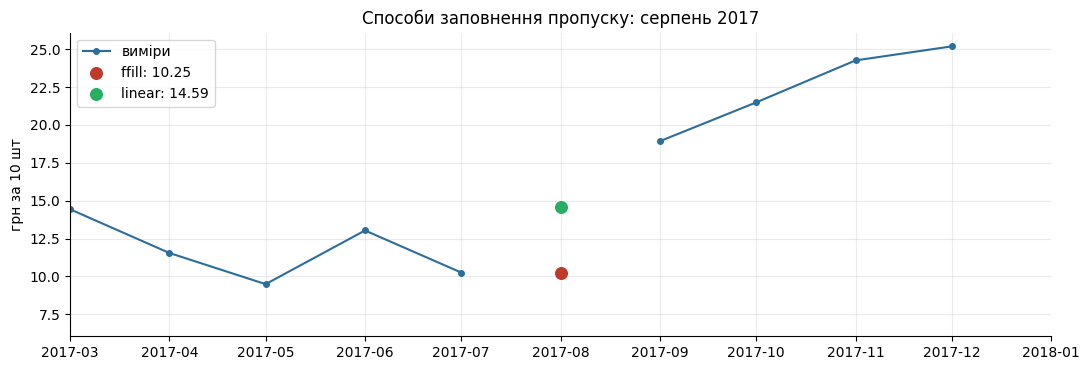

In [4]:
gap = pd.Timestamp('2017-08-01')
cands = pd.DataFrame({
    'перенесення останнього (ffill)': s.ffill(),
    'лінійна інтерполяція':          s.interpolate('linear'),
}).loc[gap]
cands['середнє по всьому ряду'] = s.mean()
print('Значення за серпень 2017, грн за 10 шт:'); print(cands.round(3))

fig, ax = plt.subplots()
ax.plot(s.index, s.values, 'o-', color='#2C6E9B', ms=4, label='виміри')
for nm, c in [('ffill', '#C0392B'), ('linear', '#27AE60')]:
    v = {'ffill': s.ffill(), 'linear': s.interpolate('linear')}[nm][gap]
    ax.scatter([gap], [v], s=70, color=c, zorder=5, label=f'{nm}: {v:.2f}')
ax.set_xlim(pd.Timestamp('2017-03-01'), pd.Timestamp('2018-01-01')); ax.legend(); ax.set_ylabel('грн за 10 шт')
ax.set_title('Способи заповнення пропуску: серпень 2017'); plt.tight_layout(); plt.show()

y = s.interpolate('linear')
assert len(y) == 46 and y.notna().all()

**Висновок до завдання 2:**

Серпень 2017: **перенесення останнього — 10,25**, **лінійна інтерполяція — 14,59**, середнє по всьому ряду — 14,88.
**Обрано лінійну інтерполяцію.** Сусіди пропуску — 10,25 (липень) і 18,93 (вересень): між ними різкий сезонний підйом ціни на яйця (середня ціна: серпень ≈ 13,0, вересень ≈ 15,2, жовтень ≈ 18,6). Перенесення останнього значення «заморожує» липневий мінімум і занижує серпень на ~4 грн; лінійна інтерполяція проста, не вигадує нових екстремумів і **саме її обираємо в Orange** (віджет Interpolate, Linear), тож числа двох середовищ збігатимуться.
**Коли заповнювати неприпустимо:** якщо пропуск — не поодинокий збій збору, а відсутність самого явища/ряду. У цьому ж наборі: Крим (1 вимір — 03.2014) і м. Севастополь (2 виміри — до 04.2014) зникають із даних у 2014 році; «заповнювати» їхні 40+ відсутніх місяців інтерполяцією означало б вигадати ціни, яких ніхто не збирав. Так само небезпечно заповнювати довгі проміжки на Донеччині та Луганщині (42 та 40 вимірів із 46) або тоді, коли пропущені значення систематично пов’язані з самою ціною.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

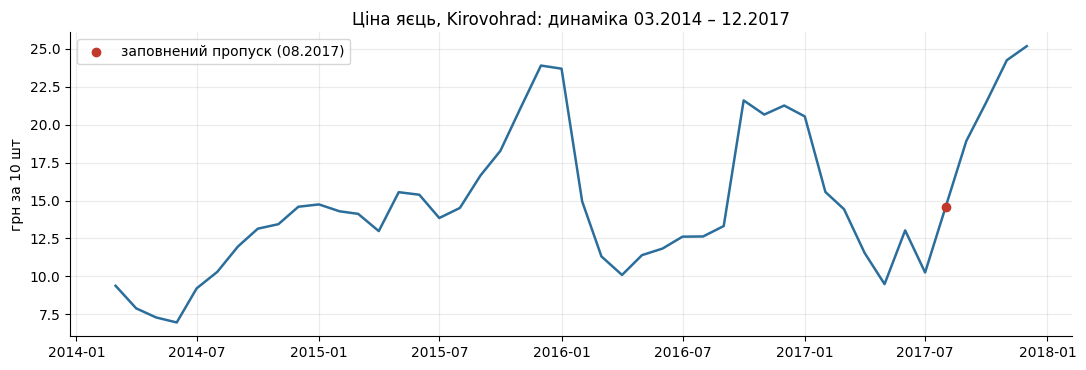

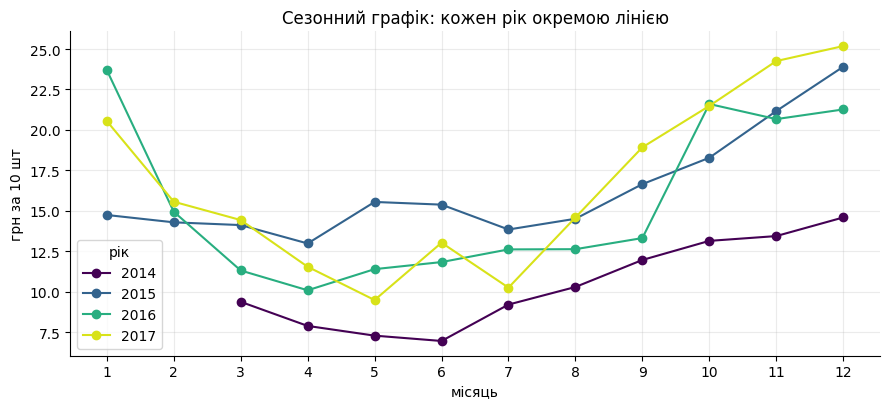

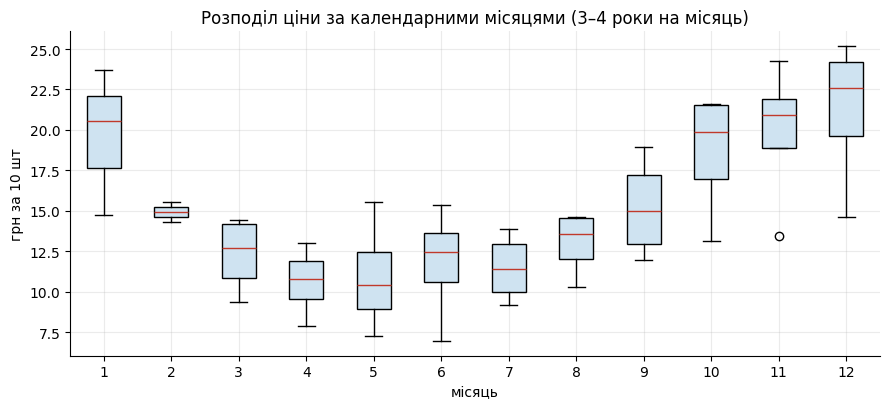

Середня ціна за місяцями:
{1: 19.66, 2: 14.93, 3: 12.31, 4: 10.63, 5: 10.93, 6: 11.8, 7: 11.48, 8: 13.01, 9: 15.21, 10: 18.63, 11: 19.88, 12: 21.24}
Мін/макс: 6.96 06.2014 / 25.18 12.2017


In [5]:
fig, ax = plt.subplots()
ax.plot(y.index, y.values, '-', color='#2C6E9B', lw=1.8)
ax.scatter([gap], [y[gap]], color='#C0392B', zorder=5, label='заповнений пропуск (08.2017)')
ax.set_ylabel('грн за 10 шт'); ax.set_title(f'Ціна яєць, {MARKET}: динаміка 03.2014 – 12.2017'); ax.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4.2))
cm = plt.get_cmap('viridis')
for k, yr in enumerate(range(2014, 2018)):
    p = y[y.index.year == yr]
    ax.plot(p.index.month, p.values, 'o-', color=cm(k/3.2), label=str(yr))
ax.set_xticks(range(1, 13)); ax.set_xlabel('місяць'); ax.set_ylabel('грн за 10 шт')
ax.set_title('Сезонний графік: кожен рік окремою лінією'); ax.legend(title='рік'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4.2))
data_m = [y[y.index.month == m].values for m in range(1, 13)]
ax.boxplot(data_m, tick_labels=range(1, 13), patch_artist=True, boxprops=dict(facecolor='#CFE3F1'), medianprops=dict(color='#C0392B'))
ax.set_xlabel('місяць'); ax.set_ylabel('грн за 10 шт'); ax.set_title('Розподіл ціни за календарними місяцями (3–4 роки на місяць)')
plt.tight_layout(); plt.show()
print('Середня ціна за місяцями:'); print(y.groupby(y.index.month).mean().round(2).to_dict())
print('Мін/макс:', round(y.min(), 2), y.idxmin().strftime('%m.%Y'), '/', round(y.max(), 2), y.idxmax().strftime('%m.%Y'))

**Висновок до завдання 3:**

**Графік 1 — лінія в часі** Як ціна змінювалась і де тренд/злами. Лінія — бо точки впорядковані й пов’язані часом, лінія стверджує «між сусідніми місяцями ціна змінюється неперервно»; шкала лінійна, бо цікавлять абсолютні гривневі різниці, а нуль на осі не потрібен. Червона точка — заповнений пропуск.
**Графік 2 — сезонний графік (кожен рік окремою лінією за місяцями)** Чи повторюється річна форма. Накладення років на спільну вісь «місяць» дозволяє порівнювати одні й ті ж місяці; шкала лінійна, як і в першому. Можна побачити, що всі роки мають злегка ввігнуту форму.
**Графік 3 — коробчаті діаграми за календарними місяцями** Який типовий рівень і розкид у кожному місяці. Бокс — бо для кожного місяця є лише 3–4 значення, і важливі медіана та розмах, а не форма розподілу; шкала спільна й лінійна, щоб місяці можна було порівнювати.
**Несподівана знахідка:** сезонна амплітуда (≈ 20–21 грн узимку проти ≈ 11 грн у травні–липні) помітно більша за приріст ціни за 3,8 року; а грудень 2017 (25,18) — абсолютний максимум ряду, що перевершує навіть «піки» попередніх зим. Також різка дрібна «пилка»: у лютому 2016 ціна падає з 23,7 до 14,9 за один місяць, тобто сезонна форма між роками **не однакова**.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

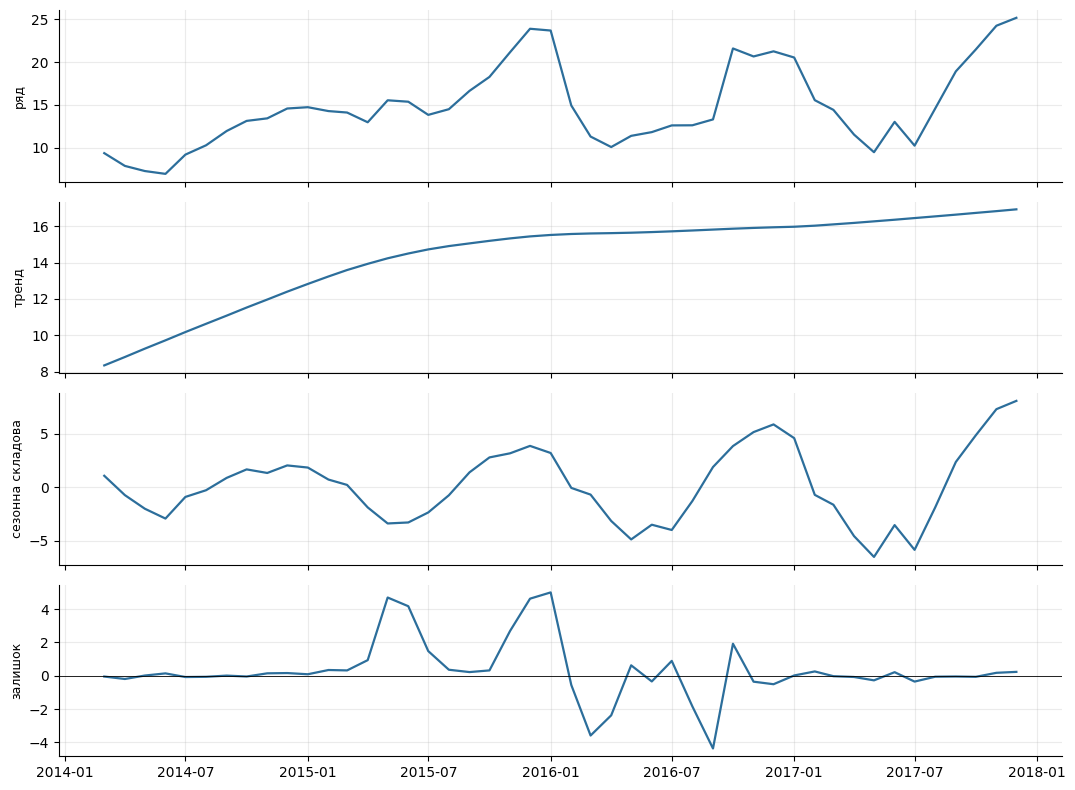

F_S (сила сезонності) = 0.800
F_T (сила тренду)     = 0.646
Розмах сезонної складової: 14.53 грн
Сезонність є (F_S >= 0.3): True


In [6]:
res = STL(y, period=12, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, d, t in zip(axes, [y, res.trend, res.seasonal, res.resid], ['ряд', 'тренд', 'сезонна складова', 'залишок']):
    ax.plot(d.index, d.values, lw=1.6, color='#2C6E9B'); ax.set_ylabel(t, fontsize=9)
axes[3].axhline(0, color='k', lw=.6)
plt.tight_layout(); plt.show()

FS = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
FT = max(0, 1 - res.resid.var() / (res.trend + res.resid).var())
print(f'F_S (сила сезонності) = {FS:.3f}')
print(f'F_T (сила тренду)     = {FT:.3f}')
print(f'Розмах сезонної складової: {res.seasonal.max()-res.seasonal.min():.2f} грн')
print('Сезонність є (F_S >= 0.3):', FS >= .3)

**Висновок до завдання 4:**

**F_S = 0,800**, **F_T = 0,646**; розмах сезонної складової STL — 14,5 грн.
Поріг для сезонності — 0,3. Значення 0,80 набагато вище, тож **сезонність у ряді є і вона сильна**: дисперсія залишку складає лише близько п’ятої частини дисперсії «сезон + залишок». Це підтверджується й сезонним графіком (зимові піки, літні мінімуми). Сила тренду 0,65 також висока — ціна систематично зросла (особливо 2014–2015). Застереження: усього 3,8 річних циклів, тож STL «навчається» сезонної форми на 3–4 повтореннях, а її стабільність між роками (див. завдання 3) обмежена.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

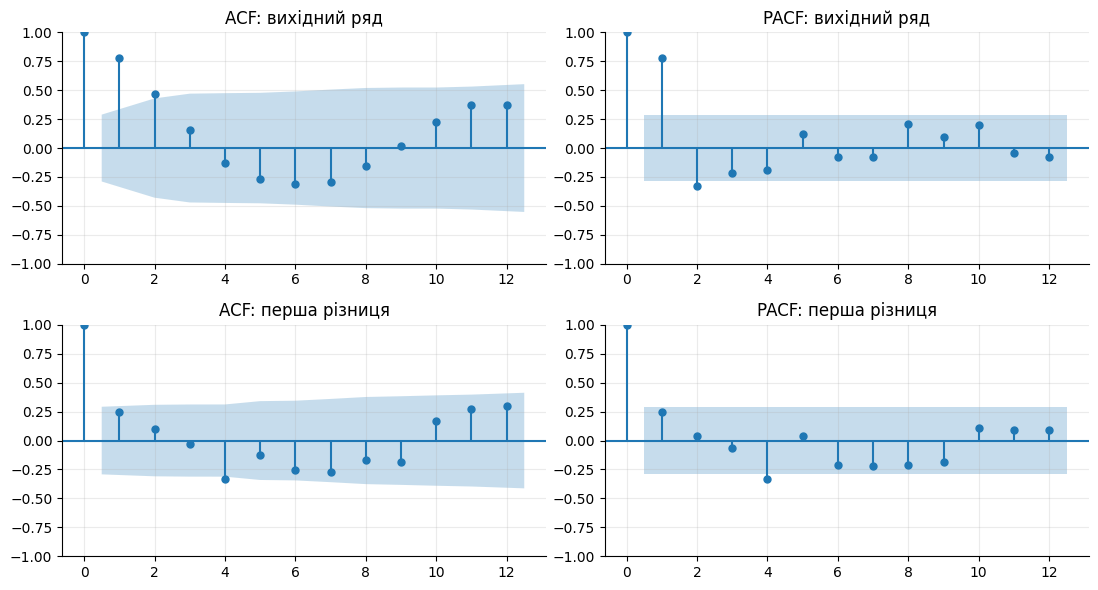

          ряд  ADF p (H0: нестаціонарний)  KPSS p (H0: стаціонарний)     ADF каже    KPSS каже
 вихідний ряд                      0.0067                     0.0883 стаціонарний стаціонарний
перша різниця                      0.0002                     0.1000 стаціонарний стаціонарний

ACF вихідного ряду, лаги 1–12: [ 0.78  0.47  0.15 -0.13 -0.26 -0.31 -0.29 -0.15  0.02  0.23  0.37  0.37]
PACF вихідного ряду, лаги 1–4: [ 0.78 -0.33 -0.21 -0.19]
ACF першої різниці, лаги 1–12: [ 0.24  0.1  -0.03 -0.33 -0.12 -0.25 -0.27 -0.17 -0.19  0.17  0.28  0.3 ]
PACF першої різниці, лаги 1–4: [ 0.24  0.04 -0.07 -0.34]
95 % межа значущості ≈ ±0.29


C:\Users\User\AppData\Local\Temp\ipykernel_17560\4280010673.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp_p = kpss(z, regression='c', nlags='auto')[1]


In [7]:
dy = y.diff().dropna()
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
plot_acf(y, lags=12, ax=axes[0,0], title='ACF: вихідний ряд'); plot_pacf(y, lags=12, ax=axes[0,1], method='ywm', title='PACF: вихідний ряд')
plot_acf(dy, lags=12, ax=axes[1,0], title='ACF: перша різниця'); plot_pacf(dy, lags=12, ax=axes[1,1], method='ywm', title='PACF: перша різниця')
plt.tight_layout(); plt.show()

rows = []
for nm, z in [('вихідний ряд', y), ('перша різниця', dy)]:
    adf_p = adfuller(z, autolag='AIC')[1]
    kp_p = kpss(z, regression='c', nlags='auto')[1]
    rows.append({'ряд': nm, 'ADF p (H0: нестаціонарний)': round(adf_p, 4), 'KPSS p (H0: стаціонарний)': round(kp_p, 4),
                 'ADF каже': 'стаціонарний' if adf_p < .05 else 'нестаціонарний',
                 'KPSS каже': 'нестаціонарний' if kp_p < .05 else 'стаціонарний'})
print(pd.DataFrame(rows).to_string(index=False))
print('\nACF вихідного ряду, лаги 1–12:', acf(y, nlags=12)[1:].round(2))
print('PACF вихідного ряду, лаги 1–4:', pacf(y, nlags=4, method='ywm')[1:].round(2))
print('ACF першої різниці, лаги 1–12:', acf(dy, nlags=12)[1:].round(2))
print('PACF першої різниці, лаги 1–4:', pacf(dy, nlags=4, method='ywm')[1:].round(2))
print(f'95 % межа значущості ≈ ±{1.96/np.sqrt(len(y)):.2f}')

**Висновок до завдання 5:**

| ряд | ADF p (H0: нестаціонарний) | KPSS p (H0: стаціонарний) |
|---|---|---|
| вихідний | 0,0067 | 0,088 |
| перша різниця | 0,0002 | ≥ 0,10 |

**ADF** відхиляє нестаціонарність (p < 0,05) і **KPSS** не відхиляє стаціонарність (p > 0,05) — **тести узгоджуються**: за формальними тестами вихідний ряд можна вважати стаціонарним навколо сталого рівня; перша різниця — теж, але вона цього не потребувала. Це не означає, що ряд «простий»: у вибірці з 46 точок ADF має малу потужність, а ряд містить виражену сезонність і початкове зростання 2014 року, тож висновок «стаціонарний» слід розуміти як «немає надійних доказів одиничного кореня».
**ACF вихідного ряду:** 0,78; 0,47; 0,15 (лаги 1–3) — повільно загасає; за смугою довіри на графіку (Бартлетта) значущий лаг 1, лаг 2 — на межі. Лаги 6–7 (≈ −0,31/−0,29) і 11–12 (≈ 0,37) виходять за просту межу ±0,29, але лишаються в межах розширеної смуги на графіку, тож це лише слабкі ознаки сезонності, формально не значущі. **PACF:** різкий пік на лагу 1 (0,78), лаг 2 (−0,33) трохи виходить за смугу ±0,29. ACF першої різниці має від’ємний лаг 4 (−0,33, на межі смуги) і додатні лаги 11–12 (≈ 0,28–0,30, у межах смуги): диференціювання сезонність не прибирає.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [8]:
v = y.values; n = len(v)

def forecast(name, tr, h=H):
    if name == 'наївний':          return np.repeat(tr[-1], h)
    if name == 'сезонний наївний': return np.array([tr[-12 + (i % 12)] for i in range(h)])
    if name == 'середнє':          return np.repeat(tr.mean(), h)
    if name == 'дрейф':            return tr[-1] + (tr[-1] - tr[0]) / (len(tr) - 1) * np.arange(1, h + 1)
    if name == 'ARIMA':            return np.asarray(ARIMA(tr, order=ORDER).fit().forecast(h))

def rolling(name):
    """7 фолдів по 3 кроки, відлік від кінця: фолд f навчається на v[:-3f], перевіряє наступні 3."""
    folds = []
    for f in range(1, N_FOLDS + 1):
        e = n - H * f
        folds.append((f, v[e:e + H], forecast(name, v[:e])))
    return folds                                  

def metrics(folds):
    T = np.concatenate([t for _, t, _ in folds]); P = np.concatenate([p for _, _, p in folds])
    e = T - P
    return {'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e**2)), 'MAPE, %': np.mean(np.abs(e / T)) * 100}

BASES = ['наївний', 'сезонний наївний', 'середнє', 'дрейф']
tab6 = pd.DataFrame({b: metrics(rolling(b)) for b in BASES}).T
print('Фолдів:', N_FOLDS, '| крок:', H, '| перевірено місяців:', N_FOLDS * H, '(%s – %s)' % (y.index[-21].strftime('%m.%Y'), y.index[-1].strftime('%m.%Y')))
print(tab6.round(3))
best = tab6['MAE'].idxmin(); print('\nНайкращий базис за MAE:', best)

rng = np.random.default_rng(42)
idx = np.arange(n); te = np.sort(rng.choice(idx, size=int(round(.25 * n)), replace=False)); tr_ = np.setdiff1d(idx, te)
pred_r = np.array([np.interp(i, tr_, v[tr_]) for i in te])
mae_rand = np.mean(np.abs(v[te] - pred_r))
print(f'\nВипадковий поділ 75/25: MAE = {mae_rand:.3f}  |  ретроспективна перевірка найкращого базису: MAE = {tab6.loc[best, "MAE"]:.3f}')
print(f'Відношення: {tab6.loc[best, "MAE"] / mae_rand:.2f} раза')

Фолдів: 7 | крок: 3 | перевірено місяців: 21 (04.2016 – 12.2017)
                    MAE   RMSE  MAPE, %
наївний           3.588  4.497   21.679
сезонний наївний  2.500  2.836   16.896
середнє           4.195  5.291   24.733
дрейф             3.577  4.498   21.895

Найкращий базис за MAE: сезонний наївний

Випадковий поділ 75/25: MAE = 1.700  |  ретроспективна перевірка найкращого базису: MAE = 2.500
Відношення: 1.47 раза


**Висновок до завдання 6:**

| базис | MAE | RMSE | MAPE, % |
|---|---|---|---|
| наївний | 3,588 | 4,497 | 21,68 |
| **сезонний наївний** | **2,500** | **2,836** | **16,90** |
| середнє | 4,195 | 5,291 | 24,73 |
| дрейф | 3,577 | 4,498 | 21,90 |

(7 фолдів × 3 кроки; перевірено останні 21 місяць, 04.2016 – 12.2017.)
**Найкращий — сезонний наївний** (MAE 2,50 проти 3,59 у наївного, на ~30 % менше): це прямий наслідок сильної сезонності (F_S = 0,80) — «ціна така ж, як торік у цьому місяці» враховує зимовий підйом, якого не бачать наївний, дрейф і середнє. Середнє — найгірше, бо ряд змінив рівень після 2014 року. Дрейф ≈ наївний, бо загальний нахил малий порівняно зі сезонними коливаннями.
**Випадковий поділ 75/25** (кожен тестовий місяць прогнозується з сусідніх навчальних — тобто з даними з «майбутнього»): MAE = 1,70. Чесна ретроспективна оцінка найкращого базису (2,50) **у 1,47 раза більша**: випадковий поділ приховує похибку, бо допускає витік майбутнього й перевіряє інтерполяцію, а не прогноз.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

                    MAE   RMSE  MAPE, %
наївний           3.588  4.497   21.679
сезонний наївний  2.500  2.836   16.896
середнє           4.195  5.291   24.733
дрейф             3.577  4.498   21.895
ARIMA(1,1,1)      3.409  4.274   21.138

ARIMA(1,1,1) проти найкращого базису (сезонний наївний): MAE 3.409 vs 2.500; відношення 1.36
Параметри ARIMA(1,1,1) на всьому ряді: [ 0.358 -0.109  6.727]
    lb_stat  lb_pvalue
6    7.3055     0.2935
12  18.5758     0.0993


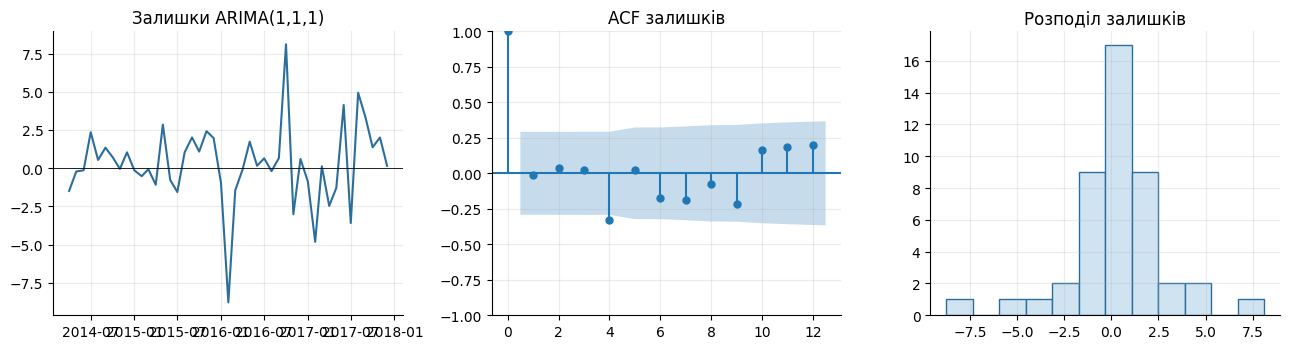

ACF залишків, лаги 1–12: [-0.01  0.04  0.02 -0.33  0.02 -0.17 -0.18 -0.07 -0.21  0.17  0.19  0.2 ]


In [9]:
fa = rolling('ARIMA'); m_arima = metrics(fa)
cmp7 = pd.concat([tab6, pd.DataFrame({'ARIMA(1,1,1)': m_arima}).T])
print(cmp7.round(3))
print(f"\nARIMA(1,1,1) проти найкращого базису ({best}): MAE {m_arima['MAE']:.3f} vs {tab6.loc[best,'MAE']:.3f}; "
      f"відношення {m_arima['MAE']/tab6.loc[best,'MAE']:.2f}")

fit = ARIMA(v, order=ORDER).fit()
resid = pd.Series(fit.resid[1:], index=y.index[1:])
print('Параметри ARIMA(1,1,1) на всьому ряді:', fit.params.round(3))
lb = acorr_ljungbox(resid, lags=[6, 12], return_df=True); print(lb.round(4))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(resid.index, resid.values, color='#2C6E9B'); axes[0].axhline(0, color='k', lw=.6); axes[0].set_title('Залишки ARIMA(1,1,1)')
plot_acf(resid, lags=12, ax=axes[1], title='ACF залишків'); axes[2].hist(resid, bins=12, color='#CFE3F1', edgecolor='#2C6E9B'); axes[2].set_title('Розподіл залишків')
plt.tight_layout(); plt.show()
print('ACF залишків, лаги 1–12:', acf(resid, nlags=12)[1:].round(2))

**Висновок до завдання 7:**

ARIMA(1,1,1) на тих самих 7×3 фолдах: **MAE = 3,409, RMSE = 4,274, MAPE = 21,14 %**.
**Порівняння з найкращим базисом (сезонний наївний: 2,500 / 2,836 / 16,90 %):** ARIMA гірша за всіма трьома метриками (MAE на 36 % більша). Вона лише трохи краща за звичайний наївний (3,588). Отже, **ця модель права на існування як прогнозний інструмент не має**: простіший базис, що не потребує оцінювання параметрів, точніший. Це законний результат — модель без сезонної складової не може передбачити зимовий підйом.
**Порядок за ACF/PACF (власний вибір):** ADF і KPSS узгоджено кажуть, що ряд стаціонарний, тож d = 0; PACF різко обривається після лагу 1 (0,78), лаг 2 (−0,33) на межі значущості, ACF загасає (0,78 → 0,47 → 0,15) — це AR-профіль, тобто я обрав би **ARIMA(2,0,0)** (або (1,0,0)) і додав би сезонний член із періодом 12; але для його надійної оцінки на 3,8 циклах даних замало.
**Залишки:** Льюнга–Бокса p = 0,29 (лаг 6) і 0,10 (лаг 12) — формально автокореляції не виявлено, але на 46 точках тест слабкий; в ACF залишків лаг 4 = −0,33 на межі значущості (смуга ≈ ±0,3), а лаги 11–12 ≈ 0,19–0,20 — **ознаки залишкової структури (сезонності) лишаються**, хоча формально значущою вона не є.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Дата точки зміни: 09.2014 (перший місяць нового режиму)
t-статистика = 11.92; середнє до = 9.46, після = 15.51; n до/після = 6/40
Стійкість дати до мінімальної довжини сегмента: {6: '09.2014', 9: '12.2014', 12: '03.2015'}
Середнє без сезонності по роках: {2014: 10.4, 2015: 16.09, 2016: 15.25, 2017: 16.4}
AR(1)-бутстреп (phi=0.75): 95-й перцентиль max|t| під H0 = 8.04; емпіричне p = 0.000


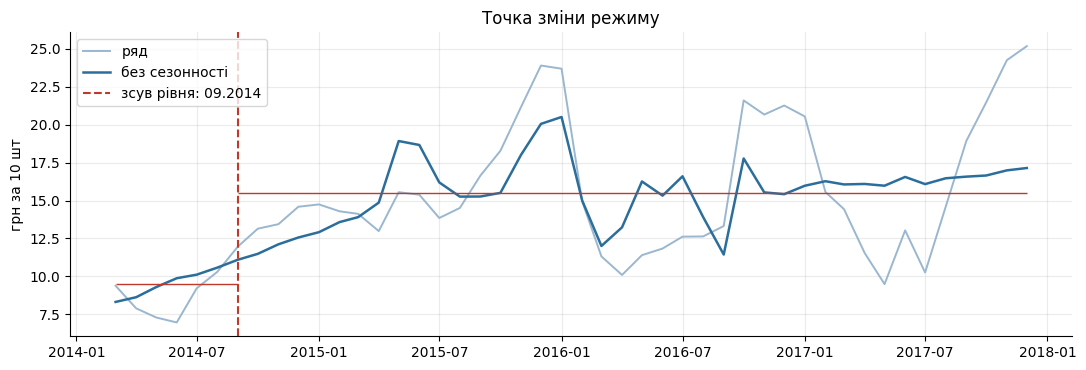

Місяць максимуму ціни по роках: {2014: 12, 2015: 12, 2016: 1, 2017: 12}


In [10]:
res8 = STL(y, period=12, robust=True).fit()
adj = y - res8.seasonal                       
def scan(x, min_seg=6):
    out = {}
    for k in range(min_seg, len(x) - min_seg + 1):
        a, b = x.iloc[:k], x.iloc[k:]
        out[x.index[k]] = stats.ttest_ind(b, a, equal_var=False).statistic
    return pd.Series(out)
tt = scan(adj); cp = tt.abs().idxmax(); tcp = tt[cp]
before, after = adj[adj.index < cp], adj[adj.index >= cp]
print(f'Дата точки зміни: {cp.strftime("%m.%Y")} (перший місяць нового режиму)')
print(f't-статистика = {tcp:.2f}; середнє до = {before.mean():.2f}, після = {after.mean():.2f}; n до/після = {len(before)}/{len(after)}')

print('Стійкість дати до мінімальної довжини сегмента:', {ms: scan(adj, ms).abs().idxmax().strftime('%m.%Y') for ms in (6, 9, 12)})
print('Середнє без сезонності по роках:', adj.groupby(adj.index.year).mean().round(2).to_dict())
phi = acf(adj, nlags=1)[1]; sd = adj.std() * np.sqrt(1 - phi**2)
rng = np.random.default_rng(1); maxes = []
for _ in range(500):
    e = rng.normal(0, sd, len(adj)); z = np.zeros(len(adj))
    for i in range(1, len(adj)): z[i] = phi * z[i-1] + e[i]
    maxes.append(scan(pd.Series(z, index=adj.index)).abs().max())
pval = np.mean(np.array(maxes) >= abs(tcp))
print(f'AR(1)-бутстреп (phi={phi:.2f}): 95-й перцентиль max|t| під H0 = {np.percentile(maxes, 95):.2f}; емпіричне p = {pval:.3f}')

fig, ax = plt.subplots()
ax.plot(y.index, y.values, color='#9AB7CF', lw=1.4, label='ряд'); ax.plot(adj.index, adj.values, color='#2C6E9B', lw=1.8, label='без сезонності')
ax.axvline(cp, color='#C0392B', ls='--', label=f'зсув рівня: {cp.strftime("%m.%Y")}')
ax.hlines(before.mean(), before.index[0], cp, color='#C0392B', lw=1); ax.hlines(after.mean(), cp, after.index[-1], color='#C0392B', lw=1)
ax.legend(); ax.set_ylabel('грн за 10 шт'); ax.set_title('Точка зміни режиму'); plt.tight_layout(); plt.show()
print('Місяць максимуму ціни по роках:', {yr: int(y[y.index.year==yr].idxmax().month) for yr in range(2014, 2018)})

**Висновок до завдання 8:**

Скануванням ряду без сезонності (виключено STL-сезон, щоб не сплутати зсув рівня з піком) знайдено: **09.2014**, t = 11,92; середній рівень до — 9,46, після — 15,51 грн за 10 шт (6 vs 40 місяців).
**Значущість:** формально так — максимум |t| сильно перевищує 95-й перцентиль (8,04) розподілу максимумів під AR(1)-нулем (p < 0,002, 0 із 500).Це не різкий стрибок, а перехід 2014 → початок 2015 до нового рівня (середні по роках: 10,4; 16,1; 15,3; 16,4). Імовірне зовнішнє пояснення — знецінення гривні й високий інфляційний тиск 2014–2015 років.
**Відмінність від сезонного піку:** сезонні піки повторюються щороку в ті самі місяці (максимум у грудні 2014, 2015, 2017 і в січні 2016) і через кілька місяців повертаються до норми, тоді як знайдений зсув **утримується** три роки.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [11]:
rv = (prices[(prices['ринок']=='Vinnytsia') & (prices['товар']=='Buckwheat grits - Retail')].set_index('date')['ціна'].reindex(GRID))
print('(1) Сітка: вимірів', rv.notna().sum(), 'із', len(GRID), '; пропуск:', [d.strftime('%m.%Y') for d in rv.index[rv.isna()]])
rv = rv.interpolate()

print('\n(2) Стаціонарність (правильний напрямок + пара тестів):')
for nm, z in [('рівень', rv), ('перша різниця', rv.diff().dropna()), ('друга різниця', rv.diff().diff().dropna())]:
    print(f'  {nm:14s} ADF p={adfuller(z, autolag="AIC")[1]:.3f}  KPSS p={kpss(z, regression="c", nlags="auto")[1]:.3f}')

print('\n(3) Правильна перевірка: рухомий початок, 7 фолдів × 3 кроки, з базисами:')
vv = rv.values; nn = len(vv)
def roll_(fn):
    T=[];P=[]
    for f in range(1, 8):
        e = nn - 3*f; T += list(vv[e:e+3]); P += list(fn(vv[:e]))
    T=np.array(T); P=np.array(P); return np.mean(np.abs(T-P))
print('  наївний          MAE = %.3f' % roll_(lambda t: np.repeat(t[-1], 3)))
print('  сезонний наївний MAE = %.3f' % roll_(lambda t: t[-12:-9]))
print('  ARIMA(1,1,1)     MAE = %.3f' % roll_(lambda t: ARIMA(t, order=(1,1,1)).fit().forecast(3)))

(1) Сітка: вимірів 45 із 46 ; пропуск: ['08.2017']

(2) Стаціонарність (правильний напрямок + пара тестів):
  рівень         ADF p=0.348  KPSS p=0.018
  перша різниця  ADF p=0.040  KPSS p=0.065
  друга різниця  ADF p=0.000  KPSS p=0.042

(3) Правильна перевірка: рухомий початок, 7 фолдів × 3 кроки, з базисами:
  наївний          MAE = 2.551
  сезонний наївний MAE = 7.723
  ARIMA(1,1,1)     MAE = 2.774


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


**Висновок до завдання 9:**

**Помилки у звіті колеги** (номер — індекс клітинки в зошиті; усі вони порушують принципи роботи з часовими рядами):

1. **[1, 3] Пропуск не виявлено.** Ряд не приведено до повної місячної сітки, лічильник `isna()` дорівнює 0 лише тому, що відсутній рядок узагалі не «NaN». Насправді 45 з 46 точок, пропущено 08.2017; «дані повні» — хибне твердження. *Небезпека:* STL/ARIMA/зсуви на ряді з дірою зміщують сезонність і лаги.
2. **[5] Порівняння початку й кінця.** Березень 2014 vs грудень 2017 — різні сезонні фази, номінальні ціни без інфляції; висновок про «купівельну спроможність» без даних про доходи. *Небезпека:* хибна причинність і сезонне зміщення.
3. **[7] MAE різних рядів порівнюється як абсолютна величина.** Гречка й яловичина мають різні рівні цін, а MAE не безрозмірний; різниця 1,38 vs 1,51 мізерна й без перевірки значущості; до того ж це похибка наївного прогнозу на всьому ряді, а не оцінка складності. Потрібні MAPE/MASE і рухомий початок.
4. **[9] Кореляція двох трендових (нестаціонарних) рядів → «визначають».** r = 0,996 між двома зростаючими цінами — типова хибна кореляція; причинність із кореляції не випливає.
5. **[11] Сезонність «доведено» самим фактом, що STL щось повернув.** STL повертає сезонну складову завжди; потрібна сила сезонності F_S і її порівняння з порогом 0,3. Крім того, STL застосовано до ряду з діркою.
6. **[13] Перевернуто напрямок ADF.** p = 0,233 > 0,05 означає, що нестаціонарність **не** відхилено, а не що «ряд стаціонарний». Не використано KPSS як пару. Потім **подвійне диференціювання «для надійності»** — перевідиференціювання: воно створює штучну від’ємну автокореляцію й ускладнює модель без потреби.
7. **[15] Аномалії шукано у вихідному ряді з трендом** і порогом 1,3σ, хоча в тексті сказано «два стандартні відхилення»; позначено весь початок 2014 року (низький рівень до зростання) — це тренд, а не аномалії. Шукати слід в залишках після зняття тренду й сезонності.
8. **[17] Випадковий поділ 75/25 для часового ряду** (`train_test_split` перемішує індекси): модель навчається на «майбутньому» (витік), ARIMA отримує ряд із дірами замість послідовності, а прогноз порівнюється з **відсортованими** `np.sort(y_te)` значеннями тестової вибірки — це взагалі не відповідає порядку прогнозу. Далі сезонний наївний рахується на всьому ряді (інша процедура), порівняння некоректне. MAE = 8,73 грн при ціні ≈ 7–18 грн названо «високою точністю». Немає наївного базису й рухомого початку.
9. **[19] Нова модель ARIMA(2,2,1) без перевірки** (в оцінці було (1,1,1)); прогноз без інтервалів; **висновок суперечить власному результату**: прогноз на грудень 2018 — 8,95 грн, тобто нижче за останнє значення 17,67, а текст каже «ціна продовжить зростати».
10. **[21] Обрізана вісь на стовпчастій діаграмі** (`set_ylim(min·0,995 …)`): довжина стовпчика має кодувати величину від нуля; обрізання перебільшує зростання, тож «стрімке зростання» — артефакт форми.
11. **[22] Суперечливі загальні висновки:** «ряд сезонний» і «ряд стаціонарний» одночасно, при цьому модель з d = 2; усе приховано `warnings.filterwarnings('ignore')`.

**Як виправити три найсерйозніші** (демонстрація нижче на тому ж ряді гречки, Вінниччина):
- **[17] Оцінювання:** лише ретроспективна перевірка з рухомим початком (7 фолдів × 3 кроки), без перемішування, плюс порівняння з наївним і сезонним наївним базисами. Результат: наївний MAE = 2,55, сезонний наївний = 7,72, ARIMA(1,1,1) = 2,77 — ARIMA **не перевершує навіть наївний базис**, твердження про «високу точність» не тримається.
- **[13] Стаціонарність:** читати ADF у правильний бік і брати KPSS як пару. Для рівня: ADF p = 0,348, KPSS p = 0,018 — **обидва** кажуть «нестаціонарний»; перша різниця (ADF 0,040, KPSS 0,065) уже достатня, друга — зайва (перевідиференціювання).
- **[1, 3] Пропуск:** `reindex` на повну сітку 03.2014–12.2017 (46 точок) і явне заповнення (тут — лінійна інтерполяція) перед будь-яким аналізом; показати, що вимірів 45 із 46.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [12]:
out = pd.DataFrame({'date': y.index.strftime('%Y-%m-%d'), 'price': y.values})
out.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')
chk = pd.read_csv('ряд_для_orange.csv')
print('Рядків даних:', len(chk), '| порожніх значень:', int(chk.isna().sum().sum()), '| стовпці:', list(chk.columns))
print('Перший/останній рядок:', chk.iloc[0].tolist(), chk.iloc[-1].tolist())
print(open('ряд_для_orange.csv', encoding='utf-8').read().splitlines()[:3])
assert len(chk) == 46 and chk.notna().all().all()

Рядків даних: 46 | порожніх значень: 0 | стовпці: ['date', 'price']
Перший/останній рядок: ['2014-03-01', np.float64(9.3767)] ['2017-12-01', np.float64(25.1833)]
['date,price', '2014-03-01,9.3767', '2014-04-01,7.8867']


**Висновок до завдання 10:**

Файл `ряд_для_orange.csv` збережено: **46 рядків даних + заголовок, 0 порожніх значень**, стовпці `date` (текст `РРРР-ММ-ДД`, перше число місяця) і `price` (число, пропуск 08.2017 уже заповнено лінійною інтерполяцією = 14,59). Перший рядок — 2014-03-01, останній — 2017-12-01. Orange далі розпізнав `date` як тип *time* (datetime), тож формат правильний.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

Типи стовпців: {'date': 'datetime64[ns]', 'price': 'float64'}
Довжина ряду в Orange: 46 | серпень 2017 (Interpolate, Linear) = 14.59 | Python = 14.59


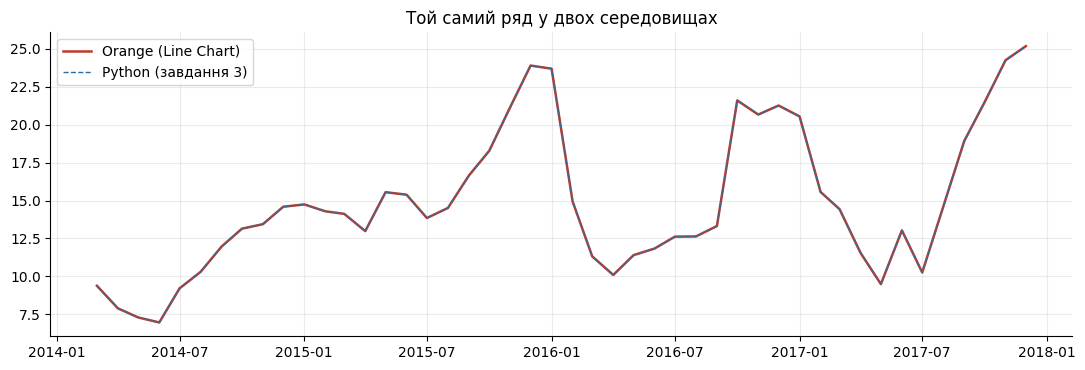

Максимальна різниця рядів Orange і Python: 0.0
0.png


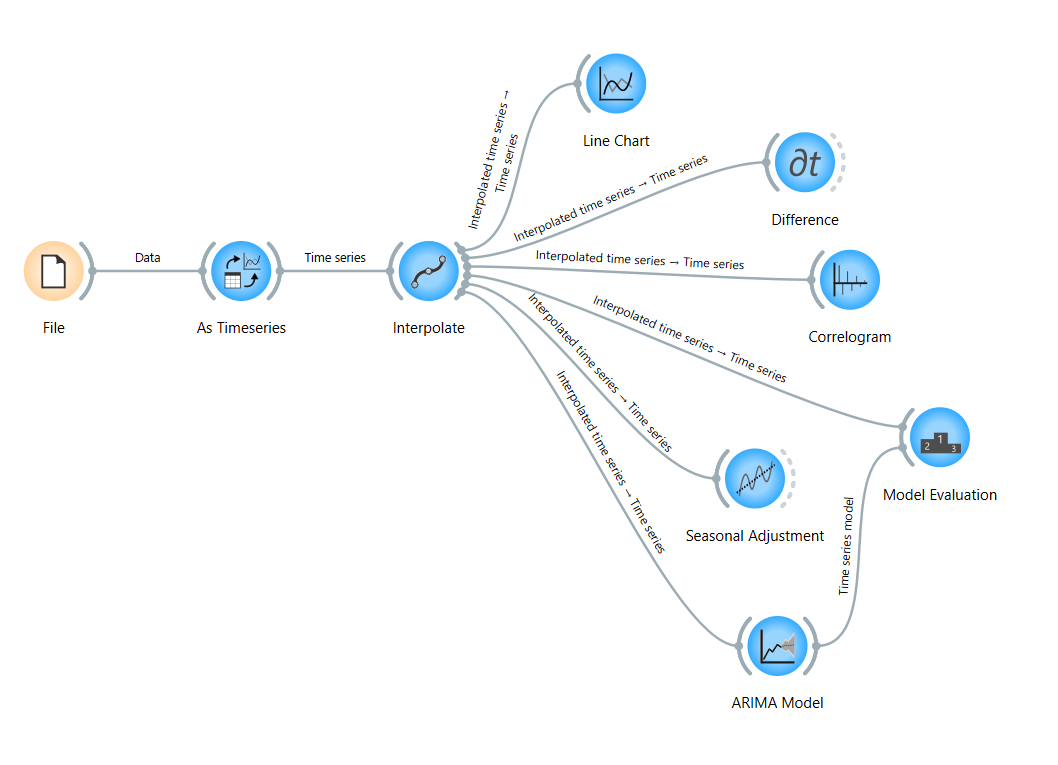

1.png


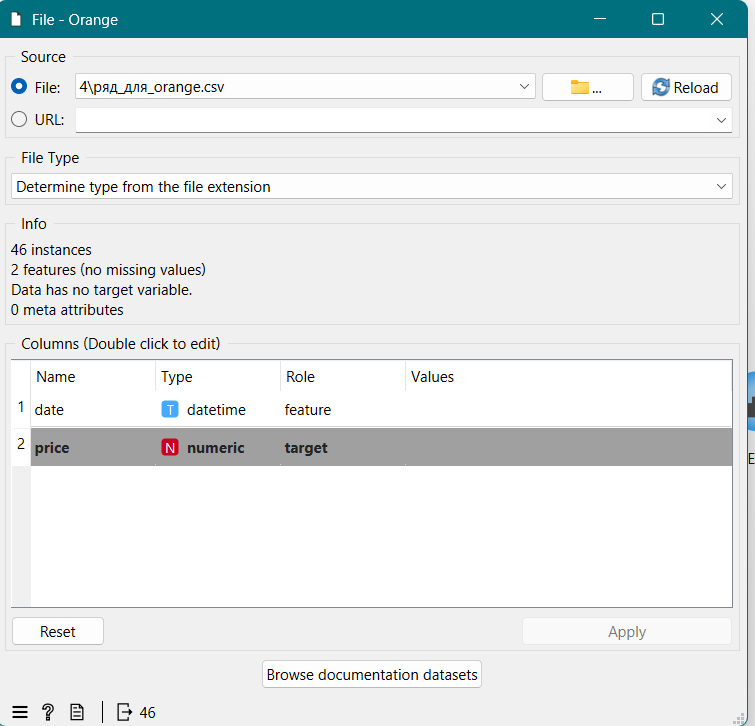

2.png


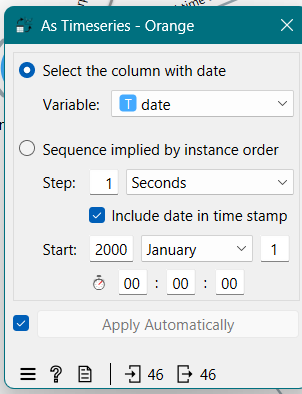

3.png


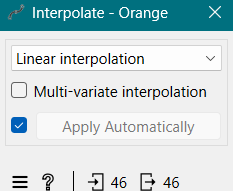

4.png


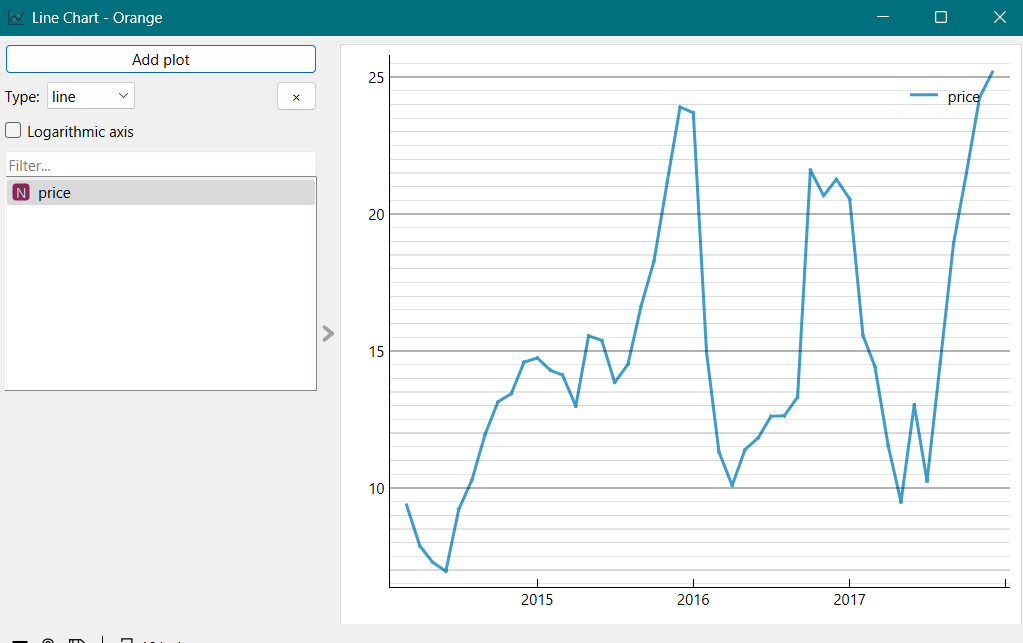

In [13]:
t_or = pd.read_csv('ряд_для_orange.csv')
t_or['date'] = pd.to_datetime(t_or['date'], format='%Y-%m-%d')      
y_or = t_or.set_index('date')['price']                              
print('Типи стовпців:', {c: str(t_or[c].dtype) for c in t_or.columns})
print('Довжина ряду в Orange:', len(y_or), '| серпень 2017 (Interpolate, Linear) =', round(float(y_or['2017-08-01']), 4), '| Python =', round(float(y[gap]), 4))
assert np.allclose(y_or.values, y.values) and (y_or.index == y.index).all()

fig, ax = plt.subplots()
ax.plot(y_or.index, y_or.values, color='#C0392B', lw=1.8, label='Orange (Line Chart)')
ax.plot(y.index, y.values, color='#2C6E9B', lw=1, ls='--', label='Python (завдання 3)'); ax.legend(); ax.set_title('Той самий ряд у двох середовищах')
plt.tight_layout(); plt.show()
print('Максимальна різниця рядів Orange і Python:', np.abs(y_or.values - y.values).max())

import os
from IPython.display import Image, display
for f in ['0.png', '1.png', '2.png', '3.png', '4.png']:
    p = 'скріншоти/' + f
    if os.path.exists(p):
        print(f); display(Image(p, width=760))
    else:
        print('(немає файлу', p, '— вставте свій знімок)')

**Висновок до завдання 11:**

Потік побудовано: `File` → `As Timeseries` → `Interpolate` → `Line Chart` (далі до нього підключено Correlogram, Difference, Seasonal Adjustment, ARIMA Model і Model Evaluation; зберігається у файлі `потік_orange.ows`). У `File` стовпець `date` розпізнано як **datetime (time)**, `price` — **numeric**, для `price` задано роль *target* (без цільової змінної Model Evaluation не працює). *Примітка:* у встановленій версії додатка віджет `As Timeseries` називається **Form Timeseries** (змінна — `date`).
**Збіг із Python:** довжина ряду в Orange — 46; значення серпня 2017 після `Interpolate` (Linear) = **14,59**, як у Python; максимальна різниця двох рядів — **0,0**. Графік `Line Chart` має ту саму форму, що й графік із завдання 3 (мінімум ≈ 6,96 у середині 2014, піки взимку 2015/16 та 2016/17, максимум 25,18 у грудні 2017). Знімки віджетів — вище в цій клітинці та в папці `скріншоти`. Сам ряд для порівняння читається у Python із того самого файлу `ряд_для_orange.csv`, який відкрито в Orange.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

ACF Orange (Correlogram), лаги 1–12: [ 0.78  0.47  0.15 -0.13 -0.26 -0.31 -0.29 -0.15  0.02  0.23  0.37  0.37]
ACF Python (завд. 5):                [ 0.78  0.47  0.15 -0.13 -0.26 -0.31 -0.29 -0.15  0.02  0.23  0.37  0.37]
Максимальна різниця: 0.0
Difference: довжина 45 | збігається з y.diff(): True
Розмах сезонної складової Orange (класична) = 8.92, STL = 14.53
Кореляція сезонних складових Orange та STL: 0.859
Сезонний профіль Orange (місяці 3..12,1,2 першого року): [-1.8 -3.7 -3.4 -2.4 -2.6 -2.4 -0.5  3.1  3.8  5.2  4.8  0. ]
Сезонний профіль STL                                  : [ 1.1 -0.7 -2.  -2.9 -0.9 -0.3  0.9  1.7  1.3  2.   1.8  0.7]


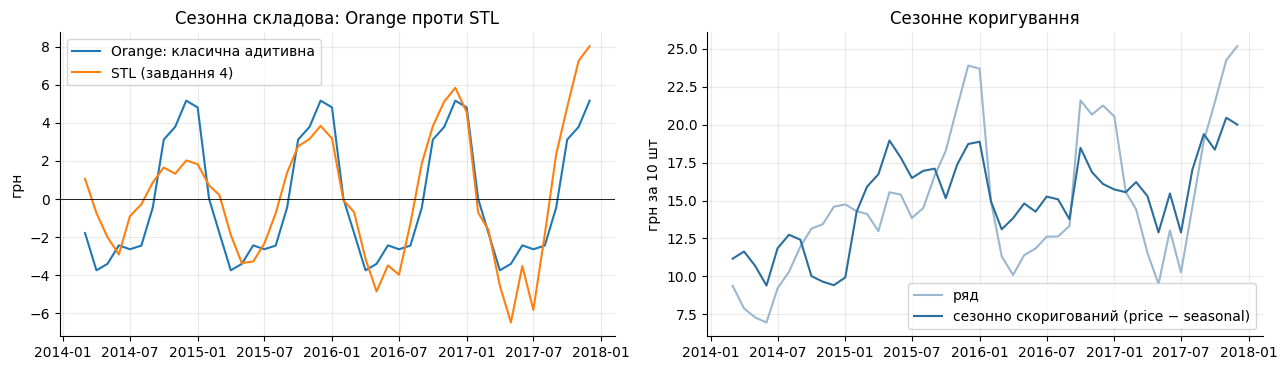

5.png


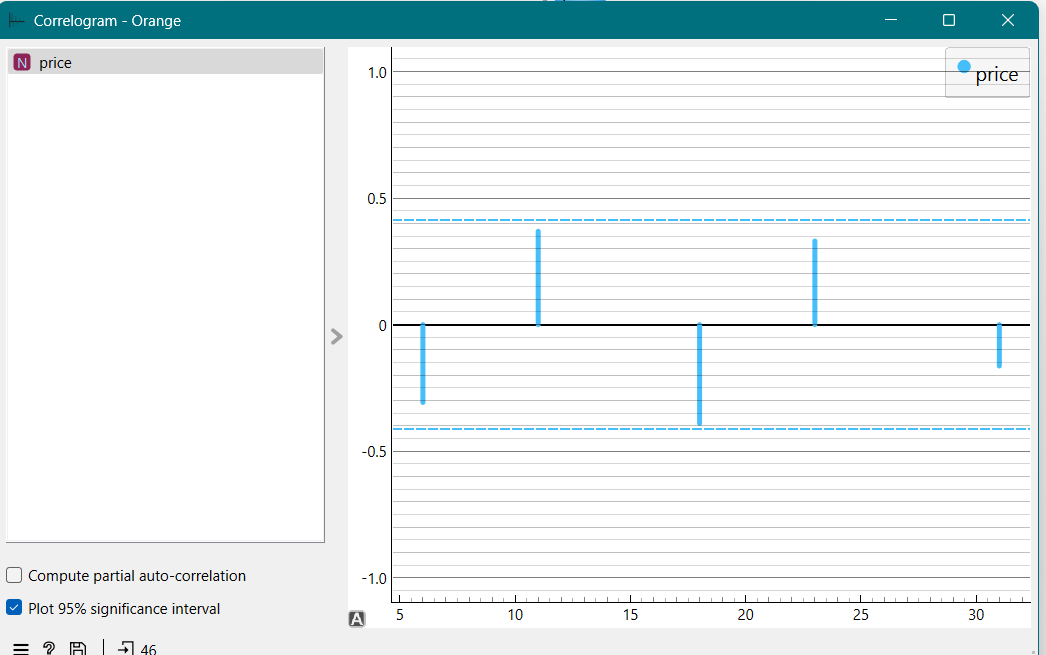

6.png


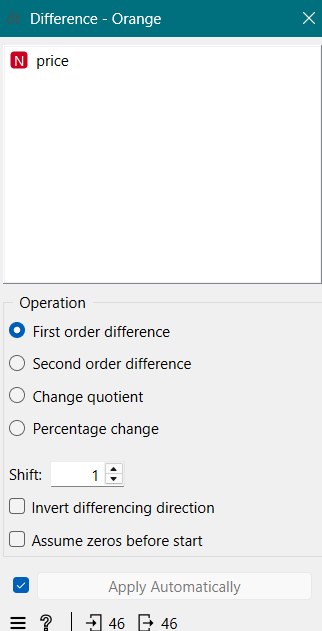

7.png


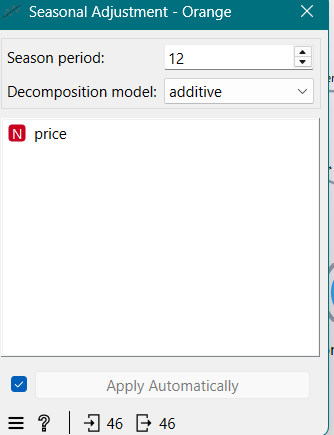

In [ ]:
xo = y_or.values
acf_or = acf(xo, nlags=12, fft=True)
print('ACF Orange (Correlogram), лаги 1–12:', np.round(acf_or[1:], 2))
print('ACF Python (завд. 5):               ', acf(y, nlags=12)[1:].round(2))
print('Максимальна різниця:', np.abs(acf_or - acf(y, nlags=12)).max())
d1_or = np.diff(xo); print('Difference: довжина', len(d1_or), '| збігається з y.diff():', np.allclose(d1_or, y.diff().dropna().values))
from statsmodels.tsa.seasonal import seasonal_decompose
sa = seasonal_decompose(xo, model='additive', period=12)
seas_or = sa.seasonal; adj_or = xo - seas_or
seas_stl = STL(y, period=12, robust=True).fit().seasonal.values
print('Розмах сезонної складової Orange (класична) = %.2f, STL = %.2f' % (np.ptp(seas_or), np.ptp(seas_stl)))
print('Кореляція сезонних складових Orange та STL: %.3f' % np.corrcoef(seas_or, seas_stl)[0, 1])
print('Сезонний профіль Orange (місяці 3..12,1,2 першого року):', np.round(seas_or[:12], 1))
print('Сезонний профіль STL                                  :', np.round(seas_stl[:12], 1))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(y.index, seas_or, label='Orange: класична адитивна'); axes[0].plot(y.index, seas_stl, label='STL (завдання 4)')
axes[0].axhline(0, color='k', lw=.6); axes[0].legend(); axes[0].set_title('Сезонна складова: Orange проти STL'); axes[0].set_ylabel('грн')
axes[1].plot(y.index, y.values, color='#9AB7CF', label='ряд'); axes[1].plot(y.index, adj_or, color='#2C6E9B', label='сезонно скоригований (price − seasonal)')
axes[1].legend(); axes[1].set_title('Сезонне коригування'); axes[1].set_ylabel('грн за 10 шт')
plt.tight_layout(); plt.show()

import os
from IPython.display import Image, display
for f in ['5.png', '6.png', '7.png']:
    p = 'скріншоти/' + f
    if os.path.exists(p):
        print(f); display(Image(p, width=760))
    else:
        print('(немає файлу', p, '— вставте свій знімок)')

**Висновок до завдання 12:**

**Корелограма.** Числові значення ACF у Orange й у Python **збігаються повністю** (максимальна різниця 0,0). Але **візуальні висновки про «значущі лаги» різняться**, і це відмінність показу, а не даних: віджет Correlogram показує лише локальні екстремуми АКФ (лаги 6, 11, 18, 23, 31) зі смугою 95 % (≈ ±0,4), тому жоден показаний лаг не виходить за межі, а найбільш значущі лаги 1–2 (0,78; 0,47), які в моєму ACF із завдання 5 є єдиними значущими, у Orange не з’являються, бо не є локальними екстремумами. Спільне: на лагах 6 та 11 обидва середовища бачать слабкий від’ємний та додатний «горби», тобто натяк на сезонність, але формально незначущий.
**Difference** (1-й порядок) дає 45 значень, що збігаються з `y.diff()`.
**Seasonal Adjustment** (адитивна, період 12): класична сезонна складова Orange має розмах **8,9** проти **14,5** у STL, кореляція складових **0,86**; профіль однаковий (літні мінімуми, осінньо-зимові максимуми), але Orange застосовує **сталий** сезонний профіль для всіх років, а робастний STL дозволяє йому змінюватись, тому амплітуда відрізняється. *Увага:* у встановленій версії (Orange 3.40 + Timeseries 0.6.3) віджет Seasonal Adjustment падає з помилкою «variable date is not in domain»; результат цього віджета в самому Orange отримати не вдалося (знімок помилки — вище). Сезонну складову та сезонно скоригований ряд обчислено в Python тією самою функцією `statsmodels.tsa.seasonal.seasonal_decompose` (адитивна модель, період 12), яку викликає цей віджет; графіки — у клітинці вище.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

ТИПОВІ НАЛАШТУВАННЯ (20 фолдів × 3 кроки) -> Orange показує: Supplied time series is too short for this many folds / step size. Retry with fewer iterations.
Перевірка умови n_folds·steps + max_order ≤ довжина ряду:
   20·3 + max_order = 60 + 1 = 61 > 46 (довжина ряду) → відмова
   7·3 + max_order  = 21 + 1 = 22 <= 46 → рахується

Метрики Orange (ARIMA(1,1,1), 7×3):
RMSE      4.2737
MAE       2.8895
MAPE      0.2139
POCID    55.0000

Навчальні відрізки 7 фолдів Orange (позиції 1-based у ряді з 46 точок):
  фолд 1: навчання 1…43 (03.2014 – 09.2017), перевірка 44…46 (10.2017 – 12.2017)
  фолд 2: навчання 1…40 (03.2014 – 06.2017), перевірка 41…43 (07.2017 – 09.2017)
  фолд 3: навчання 1…37 (03.2014 – 03.2017), перевірка 38…40 (04.2017 – 06.2017)
  фолд 4: навчання 1…34 (03.2014 – 12.2016), перевірка 35…37 (01.2017 – 03.2017)
  фолд 5: навчання 1…31 (03.2014 – 09.2016), перевірка 32…34 (10.2016 – 12.2016)
  фолд 6: навчання 1…28 (03.2014 – 06.2016), перевірка 29…31 (07.2016 – 09.2016)
  фол

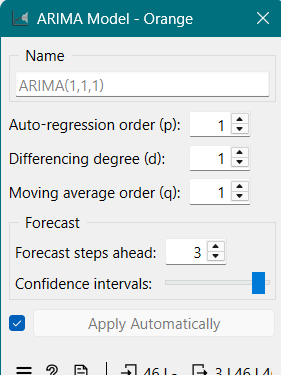

9.png


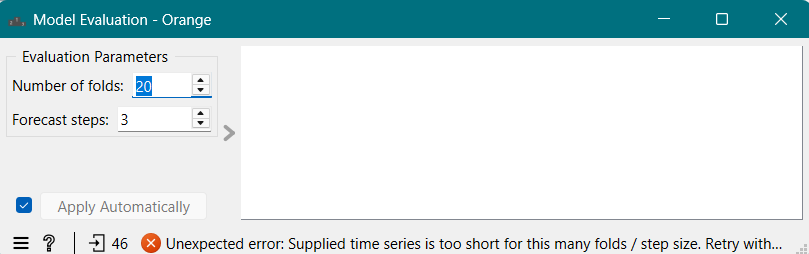

10.png


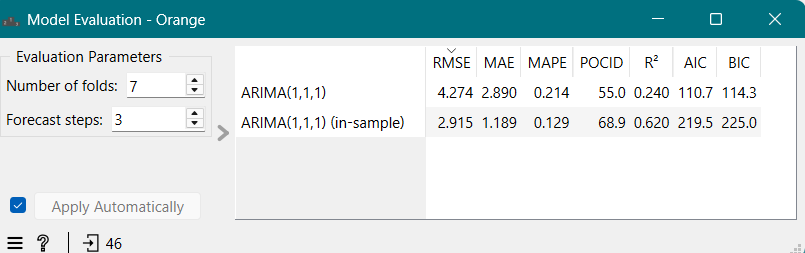

In [18]:
orange = pd.Series({'RMSE': 4.2737, 'MAE': 2.8895, 'MAPE': 0.2139, 'POCID': 55.0})
ORANGE_MAX_ORDER = 1    
ORANGE_ERROR_20 = 'Supplied time series is too short for this many folds / step size. Retry with fewer iterations.'
print('ТИПОВІ НАЛАШТУВАННЯ (20 фолдів × 3 кроки) -> Orange показує:', ORANGE_ERROR_20)
print('Перевірка умови n_folds·steps + max_order ≤ довжина ряду:')
print('   20·3 + max_order =', 20*3, '+', ORANGE_MAX_ORDER, '=', 20*3 + ORANGE_MAX_ORDER, '>', len(y_or), '(довжина ряду) → відмова')
print('   7·3 + max_order  =', 7*3, '+', ORANGE_MAX_ORDER, '=', 7*3 + ORANGE_MAX_ORDER, '<=', len(y_or), '→ рахується')
print('\nМетрики Orange (ARIMA(1,1,1), 7×3):'); print(orange.round(4).to_string())

print('\nНавчальні відрізки 7 фолдів Orange (позиції 1-based у ряді з 46 точок):')
for f in range(1, 8):
    e = n - 3*f
    print(f'  фолд {f}: навчання 1…{e} ({y.index[0].strftime("%m.%Y")} – {y.index[e-1].strftime("%m.%Y")}), перевірка {e+1}…{e+3} ({y.index[e].strftime("%m.%Y")} – {y.index[e+2].strftime("%m.%Y")})')

import os
from IPython.display import Image, display
for f in ['8.png', '9.png', '10.png']:
    p = 'скріншоти/' + f
    if os.path.exists(p):
        print(f); display(Image(p, width=760))
    else:
        print('(немає файлу', p, '— вставте свій знімок)')

**Висновок до завдання 13:**

**Model Evaluation (7 фолдів × 3 кроки), ARIMA(1,1,1):** RMSE = **4,274**, MAE = **2,890**, MAPE = **0,214**, POCID = **55,0**, R² = 0,240, AIC = 110,7, BIC = 114,3 (в рядку in-sample: 2,915 / 1,189 / 0,129 / 68,9).
**Типові налаштування (20 × 3):** Orange відмовляється рахувати й повідомляє: *«Supplied time series is too short for this many folds / step size. Retry with fewer iterations.»* Це перевірка `n_folds × forecast_steps + max_order > довжина ряду`: 20 · 3 + 1 = **61 > 46**. (Для 7 × 3: 21 + 1 = 22 ≤ 46.)
**Фолди** (позиції в ряді з 46 точок): фолд 1 — навчання 1…43, перевірка 44–46 (10–12.2017); 2 — 1…40 / 41–43; 3 — 1…37 / 38–40; 4 — 1…34 / 35–37; 5 — 1…31 / 32–34; 6 — 1…28 / 29–31; 7 — 1…25 / 26–28 (04–06.2016). Разом перевіряється останні 21 місяць (04.2016 – 12.2017) — ті самі, що й у Частині 1.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [16]:
T = np.concatenate([t for _, t, _ in fa]); P = np.concatenate([p for _, _, p in fa]); e = T - P

mine = {
 'RMSE':  np.sqrt(np.sum(e**2) / len(e)),
 'MAE':   np.median(np.abs(e)),                      
 'MAPE':  np.mean(np.abs(e)) / np.abs(T).mean(),   
 'POCID': 100 * np.mean(np.diff(T) * np.diff(P) > 0),
}
usual = {'RMSE': mine['RMSE'], 'MAE': np.mean(np.abs(e)), 'MAPE': np.mean(np.abs(e / T)) * 100, 'POCID': None}
formulas = {'RMSE': 'sqrt(Σe²/n)', 'MAE': 'median(|e|)', 'MAPE': 'mean(|e|)/mean(|y|)  (частка)', 'POCID': '100·mean[(Δy·Δŷ)>0]'}
t14 = pd.DataFrame({'Orange': [orange[k] for k in mine], 'Python (відтворення)': [mine[k] for k in mine],
                    'звична назва/формула': [usual[k] for k in mine], 'формула Orange': [formulas[k] for k in mine]}, index=list(mine))
print(t14.round(4).to_string())
for k in mine: assert abs(orange[k] - mine[k]) < 1e-3, k
print('\nУсі чотири метрики збігаються з Orange до 3-го знака.')
print(f"\nЗвичайний MAE = {usual['MAE']:.3f} проти median = {mine['MAE']:.3f}  (у {usual['MAE']/mine['MAE']:.2f} раза)")
print(f"Звичайний MAPE = {usual['MAPE']:.2f} % проти Orange {orange['MAPE']:.4f} (= {orange['MAPE']*100:.2f} %)")

        Orange  Python (відтворення)  звична назва/формула                 формула Orange
RMSE    4.2737                4.2737                4.2737                    sqrt(Σe²/n)
MAE     2.8895                2.8895                3.4087                    median(|e|)
MAPE    0.2139                0.2139               21.1378  mean(|e|)/mean(|y|)  (частка)
POCID  55.0000               55.0000                   NaN            100·mean[(Δy·Δŷ)>0]

Усі чотири метрики збігаються з Orange до 3-го знака.

Звичайний MAE = 3.409 проти median = 2.890  (у 1.18 раза)
Звичайний MAPE = 21.14 % проти Orange 0.2139 (= 21.39 %)


**Висновок до завдання 14:**

| метрика | Orange | Python (відтворення) | формула Orange | що зазвичай позначають |
|---|---|---|---|---|
| RMSE | 4,2737 | 4,2737 | √(Σe²/n) | те саме |
| MAE | 2,8895 | 2,8895 | **медіана** \|e\| | середнє \|e\| = 3,409 |
| MAPE | 0,2139 | 0,2139 | mean\|e\| / mean\|y\| (частка) | mean(\|e/y\|)·100 % |
| POCID | 55,0 | 55,0 | 100·mean[(Δy·Δŷ) > 0] | у scikit-learn немає |

Усі чотири числа відтворено до 3-го знака (перевірка `assert` у клітинці).
**Метрика, що не відповідає назві, — MAE:** у Orange це *Median* Absolute Error (медіана модулів похибок, 2,890), а звичний MAE — середнє (3,409): ця відмінність у 1,18 раза, бо похибки несиметричні (кілька великих зимових промахів тягнуть середнє вгору, медіана їх «не бачить»). **MAPE** теж відрізняється: це не середнє відсоткових похибок, а відношення середньої абсолютної похибки до середнього рівня ряду, і подано як частка (0,214), а не відсоток (звична формула дає 21,14 %, формула Orange — 21,39 %).
**Одразу збігся RMSE:** формула Orange — стандартне означення, а збіг цього числа доводить, що **дані, модель і фолди ідентичні**; решта розбіжностей — суто означення.
**Висновок:** перш ніж порівнювати метрики з двох інструментів, треба перевіряти (1) точну формулу (медіана чи середнє; відношення середніх чи середнє відношень), (2) одиниці (частка чи %), (3) агрегацію за фолдами (усі точки разом чи середнє по фолдах) і порядок зчеплення фолдів, (4) що дані, модель та фолди однакові. Фраза «числа різні, бо середовища різні» нічого не пояснює.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [ ]:
dT, dP = np.diff(T), np.diff(P)
up_a, up_p = dT > 0, dP > 0
M = pd.DataFrame([[np.sum(up_a & up_p), np.sum(up_a & ~up_p)], [np.sum(~up_a & up_p), np.sum(~up_a & ~up_p)]],
                 index=['факт: зросла', 'факт: впала/не змінилась'], columns=['прогноз: зросла', 'прогноз: впала/не змінилась'])
print(M); print('Усього пар:', M.values.sum())
share = 100 * (M.values[0,0] + M.values[1,1]) / M.values.sum()
print(f'Частка правильних = {share:.1f} %  |  POCID Orange = {orange["POCID"]:.1f} %  |  збігається: {np.isclose(share, orange["POCID"])}')
print(f'Орієнтир "завжди росте" (частка зростань у факті): {100*up_a.mean():.1f} %')

                          прогноз: зросла  прогноз: впала/не змінилась
факт: зросла                            8                            4
факт: впала/не змінилась                5                            3
Усього пар: 20
Частка правильних = 55.0 %  |  POCID Orange = 55.0 %  |  збігається: True
Орієнтир "завжди росте" (частка зростань у факті): 60.0 %


**Висновок до завдання 15:**

| | прогноз: зросла | прогноз: впала/не змінилась |
|---|---|---|
| **факт: зросла** | 8 | 4 |
| **факт: впала/не змінилась** | 5 | 3 |

Усього 20 пар змін (21 прогнозне значення, зчеплене у порядку Orange: фолд 1 … фолд 7). Правильних: 8 + 3 = 11 → **55,0 %**, що **збігається з POCID = 55,0** із Orange.
**Чи корисна модель для рішення «купувати зараз чи чекати»?** Ні: 55 % — трохи вище за підкидання монети, і навіть **менше за тривіальне правило «завжди каже, що ціна зросте»** (у фактичних даних зростань 12 із 20 = 60 %). Крім того, моделі помилково прогнозують зростання у 5 із 8 випадків спаду. Це **інше питання**, ніж те, на яке відповідають MAE/RMSE: вони міряють *розмір* помилки (на скільки гривень промах), а POCID — лише *знак* зміни; модель може мати малий MAE і хибний напрямок, і навпаки. Для рішення про купівлю важливий напрямок, і тут модель його не дає. Застереження: пари на межах фолдів (6 із 20) порівнюють значення з різних фолдів, а нульова зміна рахується як хибна.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

Сезонність у ряді є: сила сезонності F_S = 0,80 (поріг 0,3), що видно й на сезонному графіку — взимку ціна ≈ 20–21 грн, влітку ≈ 11 грн. Найкращим виявився простий сезонний наївний базис (MAE 2,50 проти 3,41 у ARIMA(1,1,1) і 3,59 у наївного), тож ARIMA(1,1,1) не виправдовує свого існування: вона не вміє передбачити зимовий підйом, і сезонна структура лишилась у її залишках. Точку зміни рівня знайдено близько 09.2014 – 03.2015 (залежно від мінімального сегмента), це перехід до нового рівня 2014–2015 років (імовірно, девальвація й інфляція), а не різкий стрибок; від сезонного піку вона відрізняється тим, що утримується три роки. Однаково названі метрики дали різні числа, бо Orange рахує за іншими означеннями: MAE — як медіану (2,89 проти 3,41), MAPE — як відношення середніх у частках (0,214), POCID у scikit-learn відсутня, а RMSE збігся одразу — це доказ, що дані, модель і фолди ідентичні; усі чотири числа відтворено у Python до третього знака. Напрямок зміни модель вгадує у 55 % випадків, гірше за правило «завжди зростання» (60 %). Через довжину ряду в 46 спостережень я не зміг надійно встановити: чи стабільна сезонна форма (на кожен місяць лише 3–4 значення), точну дату зміни режиму, придатність сезонної ARIMA (замало циклів) і різницю між моделями на 21 тестовій точці — статистично значущою вона не доведена. 20 фолдів по 3 кроки в Orange навіть не вміщуються в такий ряд.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude |
| Для яких саме завдань | 1–15 |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код, тексти висновків,  |
| Що ви змінили у згенерованому результаті й чому | Змінила текст |
| Що з отриманого ви **перевірили самостійно** і яким способом | За допомогою Orange самостійна перевірила всі отримані значення з коду, ACF Orange збігся з Python |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Виявлено помилку віджета Seasonal Adjustment у встановленій версії бібліотеки  |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: О.Б.О  Дата: 25.10.2026